# 3. Эффект в каждом эксперименте

План анализа зафиксирован в конце ноутбука 02 до расчёта эффектов. Коротко:
- основная выборка - все ученики в файле, метрика - доля завершивших, эффект - разница долей E - C;
- двусторонний z-тест для долей и перцентильный бутстреп-интервал 95% (10 000 повторов, сид 42);
- поправки на множественные сравнения и решения - на этапах 5 и 6, здесь только p-value без поправки;
- 263057 в решения не входит, его оценки справочно;
- проверки устойчивости: триггерный анализ (14 экспериментов), выборка без не видящих видео (9), 256027 с 6
  добавленными бросившими в C;
- вторичная метрика - число задач до завершения среди завершивших, в решение не входит.

In [1]:
import sys
from pathlib import Path

sys.path.insert(0, str(Path.cwd().parent))

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from src import config, db, effects, stats

pd.set_option("display.max_columns", 40)
pd.set_option("display.width", 200)
con = db.connect()
rng = np.random.default_rng(config.SEED)
EXCLUDED = effects.EXCLUDED

In [2]:
wide = effects.completion_wide(con)

## Основная выборка

Разница и границы интервала - в долях (0,03 = 3 п.п.).

In [3]:
main = effects.effects(wide[wide["sample"] == "all"], rng)
main.round(4)

,experiment_id,n_c,n_e,rate_c,rate_e,diff,z,p,boot_lo,boot_hi,wald_lo,wald_hi
0,226210,607,578,0.6804,0.6349,-0.0454,-1.6487,0.0992,-0.0992,0.0089,-0.0995,0.0086
1,237447,329,363,0.9848,0.9587,-0.0261,-2.0486,0.0405,-0.0515,-0.0019,-0.0505,-0.0018
2,241501,188,193,0.8936,0.8497,-0.0439,-1.2790,0.2009,-0.1122,0.0240,-0.1108,0.0231
3,241622,338,289,0.8817,0.8374,-0.0443,-1.5990,0.1098,-0.0991,0.0086,-0.0990,0.0104
4,243393,910,887,0.7330,0.7170,-0.0159,-0.7568,0.4491,-0.0573,0.0261,-0.0572,0.0253
5,246482,225,232,0.7333,0.7414,0.0080,0.1954,0.8451,-0.0711,0.0901,-0.0727,0.0888
6,246627,279,235,0.7240,0.6936,-0.0304,-0.7567,0.4492,-0.1081,0.0509,-0.1093,0.0485
7,246647,264,274,0.8447,0.8467,0.0020,0.0648,0.9483,-0.0576,0.0650,-0.0590,0.0631
8,250476,193,209,0.8912,0.9330,0.0418,1.4860,0.1373,-0.0136,0.0972,-0.0137,0.0973
9,255116,258,276,0.8217,0.7971,-0.0246,-0.7228,0.4698,-0.0918,0.0431,-0.0912,0.0420


In [4]:
dec = main[main.experiment_id != EXCLUDED]
print("экспериментов в решениях:", len(dec))
print("p < 0,05 без поправки:", (dec.p < 0.05).sum(), " из них эффект > 0:", ((dec.p < 0.05) & (dec["diff"] > 0)).sum())
print("бутстреп-интервал не содержит 0:", ((dec.boot_lo > 0) | (dec.boot_hi < 0)).sum())
print("верхняя граница ниже +3 п.п.:", (dec.boot_hi < 0.03).sum())
print("медианная ширина интервала, п.п.:", round(100 * (dec.boot_hi - dec.boot_lo).median(), 1))

экспериментов в решениях: 21
p < 0,05 без поправки: 1  из них эффект > 0: 0
бутстреп-интервал не содержит 0: 1
верхняя граница ниже +3 п.п.: 8
медианная ширина интервала, п.п.: 10.8


Бутстреп и интервал Вальда для доли - почти одно и то же при таких размерах групп. Проверяю, насколько расходятся
границы.

In [5]:
gap = np.maximum((main.boot_lo - main.wald_lo).abs(), (main.boot_hi - main.wald_hi).abs())
print("максимальное расхождение границ, п.п.:", round(100 * gap.max(), 2), "в", main.experiment_id[gap.idxmax()])

максимальное расхождение границ, п.п.: 0.32 в 377938


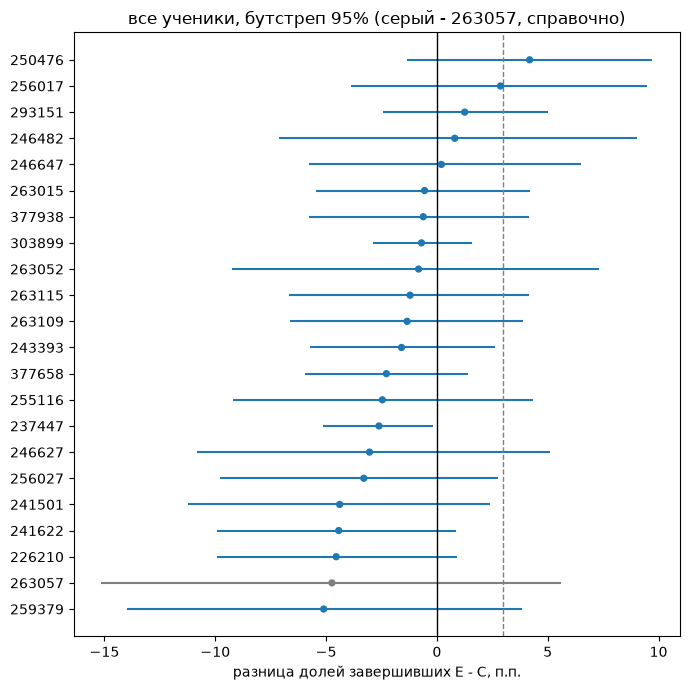

In [6]:
def forest(ax, d, title):
    d = d.sort_values("diff").reset_index(drop=True)
    colors = ["grey" if e == EXCLUDED else "C0" for e in d.experiment_id]
    ax.errorbar(100 * d["diff"], d.index, xerr=[100 * (d["diff"] - d.boot_lo), 100 * (d.boot_hi - d["diff"])],
                fmt="none", ecolor=colors, elinewidth=1.5)
    ax.scatter(100 * d["diff"], d.index, c=colors, zorder=3, s=18)
    ax.axvline(0, color="black", linewidth=1)
    ax.axvline(3, color="grey", linestyle="--", linewidth=1)
    ax.set_yticks(d.index, d.experiment_id)
    ax.set_xlabel("разница долей завершивших E - C, п.п.")
    ax.set_title(title)


fig, ax = plt.subplots(figsize=(7, 7))
forest(ax, main, "все ученики, бутстреп 95% (серый - 263057, справочно)")
plt.tight_layout()

## Проверка устойчивости: триггерный анализ

Только 14 экспериментов, где часть учеников не увидела условие, а доли увидевших в C и E не различаются. Триггерный
эффект относится к увидевшим условие. Чтобы сравнить его с основным, умножаю его на долю увидевших (размытый эффект):
если на не увидевших условие не влияет, он должен быть близок к основному.

In [7]:
groups = effects.trigger_table(con)
symmetric = groups[groups.symmetric].experiment_id

trig = effects.effects(wide[(wide["sample"] == "experienced") & wide.experiment_id.isin(symmetric)], rng)
trig = trig.merge(groups[["experiment_id", "trigger_share"]], on="experiment_id").merge(
    main[["experiment_id", "diff", "p", "boot_lo", "boot_hi"]], on="experiment_id", suffixes=("", "_all"))
trig["diluted"] = trig["diff"] * trig.trigger_share
trig[["experiment_id", "trigger_share", "diff", "p", "boot_lo", "boot_hi", "diluted", "diff_all", "p_all"]].round(4)

,experiment_id,trigger_share,diff,p,boot_lo,boot_hi,diluted,diff_all,p_all
0,226210,0.6430,-0.0640,0.0698,-0.1340,0.0062,-0.0412,-0.0454,0.0992
1,241501,0.7165,-0.0246,0.5324,-0.1050,0.0551,-0.0177,-0.0439,0.2009
2,250476,0.4925,0.0633,0.2210,-0.0379,0.1653,0.0312,0.0418,0.1373
3,256017,0.6214,0.0521,0.2652,-0.0344,0.1456,0.0324,0.0287,0.3958
4,256027,0.5313,-0.0112,0.8345,-0.1124,0.0899,-0.0060,-0.0330,0.3046
5,259379,0.7606,-0.0162,0.7535,-0.1178,0.0830,-0.0123,-0.0511,0.2552
6,263015,0.3835,-0.0605,0.2115,-0.1558,0.0339,-0.0232,-0.0056,0.8220
7,263052,0.7304,-0.0090,0.8557,-0.1052,0.0899,-0.0066,-0.0083,0.8453
8,263109,0.7313,-0.0147,0.6438,-0.0775,0.0481,-0.0107,-0.0134,0.6173
9,263115,0.5915,-0.0000,0.9991,-0.0709,0.0684,-0.0000,-0.0121,0.6606


In [8]:
same_sign = np.sign(trig["diff"]) == np.sign(trig.diff_all)
print("знак эффекта совпадает с основным:", same_sign.sum(), "из", len(trig))
print("p < 0,05 без поправки: триггерный", (trig.p < 0.05).sum(), " основной", (trig.p_all < 0.05).sum())
print("медиана |размытый - основной|, п.п.:", round(100 * (trig.diluted - trig.diff_all).abs().median(), 2))

знак эффекта совпадает с основным: 13 из 14
p < 0,05 без поправки: триггерный 1  основной 0
медиана |размытый - основной|, п.п.: 1.03


## Проверка устойчивости: без не видящих видео

Так делали авторы датасета. Признак записан после рандомизации, поэтому это не основной анализ: если вопрос-проверка
зависит от группы, фильтр ломает сравнимость. В 259379 доли не видящих видео в группах различаются (p = 0,035).

In [9]:
video = effects.effects(wide[wide["sample"] == "video_viewers"], rng).merge(
    main[["experiment_id", "n_c", "n_e", "diff", "p"]], on="experiment_id", suffixes=("", "_all"))
video["dropped_share"] = 1 - (video.n_c + video.n_e) / (video.n_c_all + video.n_e_all)
video[["experiment_id", "dropped_share", "diff", "p", "boot_lo", "boot_hi", "diff_all", "p_all"]].round(4)

,experiment_id,dropped_share,diff,p,boot_lo,boot_hi,diff_all,p_all
0,250476,0.2289,0.0387,0.1562,-0.0144,0.0924,0.0418,0.1373
1,256017,0.1456,0.0159,0.6558,-0.0533,0.0855,0.0287,0.3958
2,256027,0.1582,-0.0268,0.4599,-0.0972,0.0443,-0.0330,0.3046
3,259379,0.1891,-0.0167,0.7361,-0.1115,0.0777,-0.0511,0.2552
4,263015,0.1534,-0.0130,0.6266,-0.0669,0.0384,-0.0056,0.8220
5,263052,0.0000,-0.0083,0.8453,-0.0926,0.0739,-0.0083,0.8453
6,263109,0.2126,-0.0308,0.2825,-0.0872,0.0266,-0.0134,0.6173
7,263115,0.2706,-0.0309,0.3121,-0.0893,0.0281,-0.0121,0.6606
8,293151,0.3479,0.0002,0.9938,-0.0437,0.0416,0.0125,0.5098


In [10]:
print("знак эффекта совпадает с основным:", (np.sign(video["diff"]) == np.sign(video.diff_all)).sum(), "из", len(video))
print("p < 0,05 без поправки: без не видящих", (video.p < 0.05).sum(), " основной", (video.p_all < 0.05).sum())

знак эффекта совпадает с основным: 9 из 9
p < 0,05 без поправки: без не видящих 0  основной 0


## Проверка устойчивости: 256027 с недостающими бросившими

В 256027 в E 6 учеников бросили раньше 3-й задачи, в C ни одного. Если в C такие ученики потеряны, их там примерно
столько же. Добавляю в C 6 незавершивших и пересчитываю эффект.

In [11]:
adj = wide[(wide["sample"] == "all") & (wide.experiment_id == 256027)].copy()
adj["n_c"] += 6
sens = pd.concat([main[main.experiment_id == 256027], effects.effects(adj, rng)], ignore_index=True)
sens.insert(1, "variant", ["как в файле", "+6 бросивших в C"])
sens.drop(columns="experiment_id").round(4)

,variant,n_c,n_e,rate_c,rate_e,diff,z,p,boot_lo,boot_hi,wald_lo,wald_hi
0,как в файле,165,170,0.9212,0.8882,-0.0330,-1.0266,0.3046,-0.0980,0.0276,-0.0957,0.0297
1,+6 бросивших в C,171,170,0.8889,0.8882,-0.0007,-0.0192,0.9847,-0.0709,0.0696,-0.0675,0.0661


## 263057, справочно

В решения не входит: группы несравнимы и на полной выборке, и среди увидевших условие.

In [12]:
ref = pd.concat([main[main.experiment_id == EXCLUDED],
                 effects.effects(wide[(wide["sample"] == "experienced") & (wide.experiment_id == EXCLUDED)], rng)], ignore_index=True)
ref.insert(1, "sample", ["все", "увидевшие условие"])
ref.drop(columns="experiment_id").round(4)

,sample,n_c,n_e,rate_c,rate_e,diff,z,p,boot_lo,boot_hi,wald_lo,wald_hi
0,все,69,67,0.913,0.8657,-0.0474,-0.8817,0.3779,-0.1514,0.0558,-0.1527,0.0579
1,увидевшие условие,69,60,0.913,0.9667,0.0536,1.2595,0.2078,-0.0254,0.1304,-0.0269,0.1341


## Вторичная метрика: число задач до завершения

Только среди завершивших, поэтому это описание, а не оценка эффекта. Если условие помогло завершить слабым ученикам,
у завершивших в E будет больше задач, даже если каждому отдельному ученику условие ничего не стоило. Считаю разницу
средних log10(ProblemCount), как в статье о датасете: 10 в этой степени - отношение геометрических средних числа задач.
Сравнивать можно только группы внутри одного эксперимента.

In [13]:
done = db.run(con, "groups.sql", "completers")
rows = []
for eid, d in done.groupby("experiment_id"):
    e, c = d[d.grp == "E"].log_count.values, d[d.grp == "C"].log_count.values
    lo, hi = stats.bootstrap_mean_diff_ci(e, c, effects.N_BOOT, rng)
    rows.append({"experiment_id": eid, "n_done_c": len(c), "n_done_e": len(e),
                 "gmean_c": 10 ** c.mean(), "gmean_e": 10 ** e.mean(),
                 "diff_log": e.mean() - c.mean(), "boot_lo": lo, "boot_hi": hi})
secondary = pd.DataFrame(rows).merge(main[["experiment_id", "diff"]].rename(columns={"diff": "diff_completion"}))
secondary["ratio"] = 10 ** secondary.diff_log
secondary.round(4)

,experiment_id,n_done_c,n_done_e,gmean_c,gmean_e,diff_log,boot_lo,boot_hi,diff_completion,ratio
0,226210,413,367,4.6908,4.7333,0.0039,-0.0277,0.0370,-0.0454,1.0091
1,237447,324,348,5.7467,6.3553,0.0437,0.0083,0.0800,-0.0261,1.1059
2,241501,168,164,11.7520,13.5999,0.0634,0.0340,0.0932,-0.0439,1.1572
3,241622,298,242,12.5227,14.3368,0.0588,0.0238,0.0947,-0.0443,1.1449
4,243393,667,636,4.7088,4.6330,-0.0071,-0.0341,0.0197,-0.0159,0.9839
5,246482,165,172,4.2079,4.2370,0.0030,-0.0347,0.0388,0.0080,1.0069
6,246627,202,163,4.5098,4.4530,-0.0055,-0.0391,0.0275,-0.0304,0.9874
7,246647,223,232,3.9196,3.8775,-0.0047,-0.0366,0.0263,0.0020,0.9893
8,250476,172,195,4.3038,4.2455,-0.0059,-0.0666,0.0535,0.0418,0.9865
9,255116,212,220,11.7279,12.8626,0.0401,0.0031,0.0779,-0.0246,1.0967


In [14]:
sec = secondary[secondary.experiment_id != EXCLUDED]
print("интервал не содержит 0:", ((sec.boot_lo > 0) | (sec.boot_hi < 0)).sum(), "из", len(sec),
      " из них меньше задач в E:", (sec.boot_hi < 0).sum())

интервал не содержит 0: 5 из 21  из них меньше задач в E: 0


In [15]:
print("точечная оценка ниже нуля:", (dec["diff"] < 0).sum(), "из", len(dec))
slower = sec[sec.boot_lo > 0]
slower[["experiment_id", "ratio", "diff_completion"]].round(3)

точечная оценка ниже нуля: 16 из 21


,experiment_id,ratio,diff_completion
1,237447,1.106,-0.026
2,241501,1.157,-0.044
3,241622,1.145,-0.044
9,255116,1.097,-0.025
12,259379,1.289,-0.051


## Итог

- Основная выборка, 21 эксперимент в решениях. Без поправки p < 0,05 только в 237447: -2,6 п.п. (интервал от -5,2
  до -0,2), то есть условие снижает долю завершивших. Значимых улучшений нет. Самая большая положительная оценка -
  +4,2 п.п. в 250476 (p = 0,14). В 16 из 21 эксперимента точечная оценка ниже нуля.
- Интервалы широкие: медианная ширина 10,8 п.п. Верхняя граница ниже +3 п.п. в 8 экспериментах. Мощность и
  поправки - на этапах 4 и 5.
- Бутстреп и интервал Вальда расходятся не больше чем на 0,32 п.п. Для доли с такими группами это ожидаемо.
- Триггерный анализ (14 экспериментов): знак совпадает с основным в 13, расходится в 377938, где обе оценки около
  нуля. Размытый эффект отличается от основного в среднем (медиана) на 1,0 п.п. Единственное p < 0,05 - 293151:
  +8,4 п.п. среди увидевших условие (p = 0,040) при +1,3 п.п. на всех (p = 0,51). Это одно срабатывание из 14 до
  поправки, решение по нему не меняю.
- Без не видящих видео (9 экспериментов): знак совпадает во всех 9, p < 0,05 ни в одном. В 259379, где доли не видящих
  видео в группах различались, эффект сжимается с -5,1 до -1,7 п.п., но и там, и там незначим.
- 256027: в файле -3,3 п.п., интервал от -9,8 до +2,8. С 6 добавленными бросившими в C -0,1 п.п., интервал от -7,1
  до +7,0. Верхняя граница переходит +3 п.п., так что по зафиксированному правилу здесь будет «мало данных».
- 263057, справочно: -4,7 п.п. на всех и +5,4 п.п. среди увидевших условие. Знак меняется, это и есть следствие
  несимметричной выборки.
- Вторичная метрика. В 5 экспериментах из 21 у завершивших в E больше задач (интервал выше нуля), в обратную
  сторону ни одного: 237447, 241501, 241622, 255116, 259379, на 10-29% по геометрическому среднему. Во всех пяти
  и доля завершивших в E ниже. Простой отбор («условие отсеяло самых слабых») дал бы обратное: оставшиеся в E
  завершали бы быстрее. Но причинным эффектом это всё равно не считаю, сравниваются разные по составу группы.